In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv("cleaned_dataset_v2.3.csv")

day_cols = [c for c in df.columns if c.startswith("day_")]

long_df = df.melt(
    id_vars=[c for c in df.columns if c not in day_cols],
    value_vars=day_cols,
    var_name="day",
    value_name="strength"
)

long_df["day"] = long_df["day"].str.replace("day_", "").astype(int)


In [4]:
long_df.head()

,S,Mix_name,print_type_Cast,print_type_Printed,Nano-Silica,Fly_ash,Ultrafine_Fly_ash,Ordinary_Portland_Cement,Binder_Weight,SP,VMA,Glass_fiber,PP_fiber,Sand,Water,Mix_Weight,day,strength
0,1,O65F20U13NS2,True,False,15.55,155.54,101.1,505.51,777.7,0.7777,2.72195,3.8885,0.0,1166.55,272.2,2223.83815,1,4.258
1,2,O65F20U13NS2,True,False,15.55,155.54,101.1,505.51,777.7,0.7777,2.72195,3.8885,0.0,1166.55,272.2,2223.83815,1,3.499
2,3,O65F20U13NS2,False,True,15.55,155.54,101.1,505.51,777.7,0.7777,2.72195,3.8885,0.0,1166.55,272.2,2223.83815,1,5.701
3,4,O65F20U13NS2,False,True,15.55,155.54,101.1,505.51,777.7,0.7777,2.72195,3.8885,0.0,1166.55,272.2,2223.83815,1,3.285
4,5,O65F20U13NS2,True,False,15.55,155.54,101.1,505.51,777.7,0.7777,2.72195,1.9440,0.0,1166.55,272.2,2221.89365,1,4.952


In [5]:
features = long_df.drop(columns=["strength", "Mix_name"]).columns

constraints = {f: 0 for f in features}
constraints["day"] = -1  # 🔒 NON-INCREASING

monotone_constraints = "(" + ",".join(
    str(constraints[f]) for f in features
) + ")"


In [6]:
import xgboost as xgb

X = long_df[features]
y = long_df["strength"]

model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.8,
    monotone_constraints=monotone_constraints,
    random_state=42
)

model.fit(X, y)


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [7]:
def predict_days(model, mix_row, start_day=1, end_day=30):
    preds = []
    for d in range(start_day, end_day + 1):
        row = mix_row.copy()
        row["day"] = d
        preds.append(model.predict(pd.DataFrame([row]))[0])
    return np.array(preds)


In [8]:
import numpy as np
import pandas as pd

def predict_curve(model, mix_row, days=30):
    preds = []
    for d in range(1, days + 1):
        row = mix_row.copy()
        row["day"] = d
        preds.append(model.predict(pd.DataFrame([row]))[0])
    return np.array(preds)


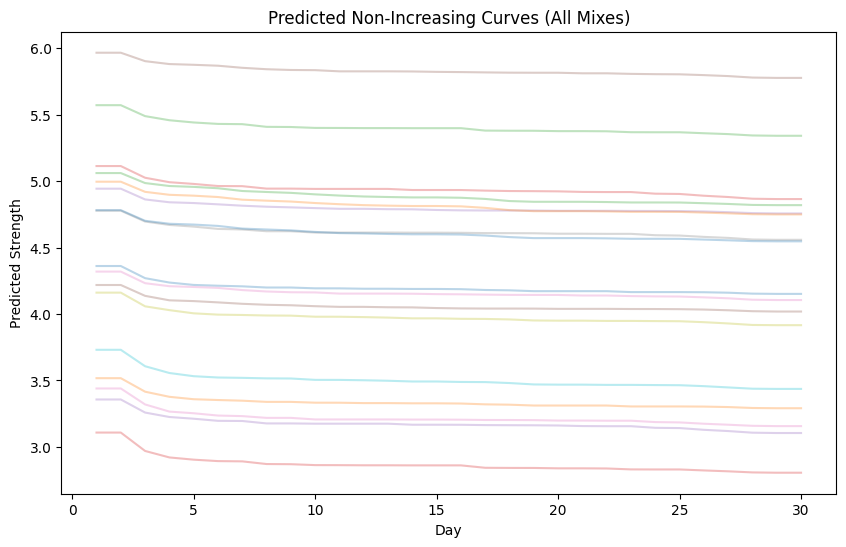

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for idx, row in df.iterrows():
    mix_features = row.drop(
        labels=[c for c in df.columns if c.startswith("day_")] + ["Mix_name"],
        errors="ignore"
    )
    
    preds = predict_curve(model, mix_features)
    plt.plot(range(1, 31), preds, alpha=0.3)

plt.xlabel("Day")
plt.ylabel("Predicted Strength")
plt.title("Predicted Non-Increasing Curves (All Mixes)")
plt.show()


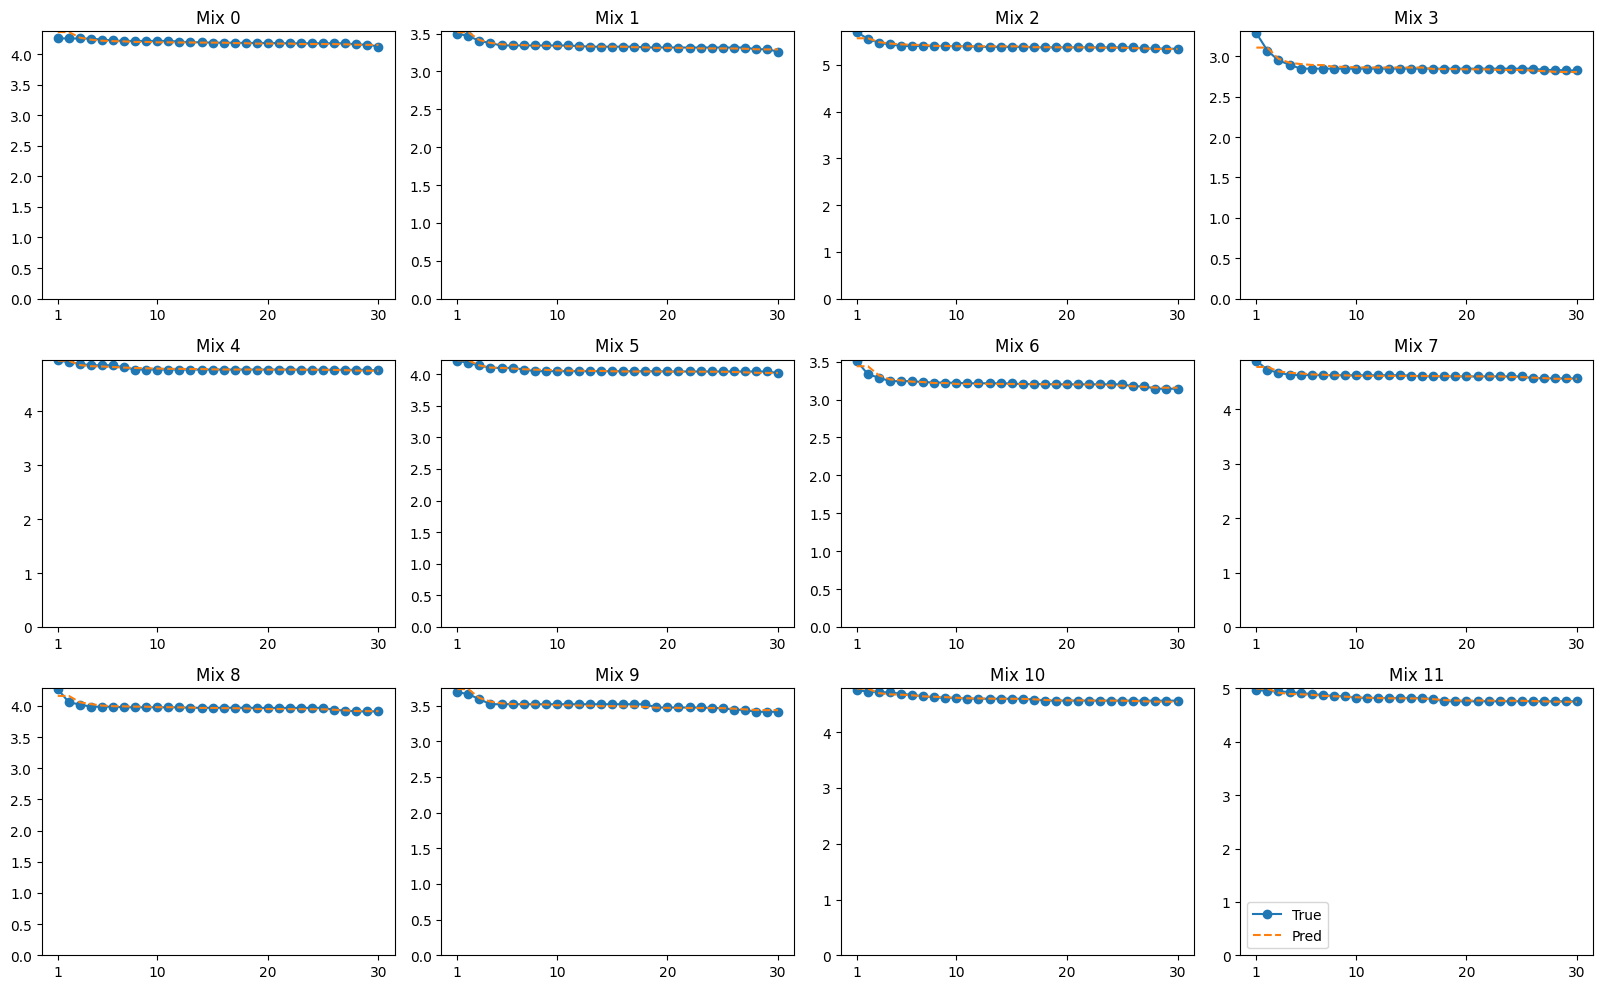

In [10]:
day_cols = [c for c in df.columns if c.startswith("day_")]

n_rows = len(df)
n_cols = 4
n_plots = min(n_rows, 12)  # cap for readability

plt.figure(figsize=(16, 10))

for i in range(n_plots):
    row = df.iloc[i]
    
    mix_features = row.drop(
        labels=day_cols + ["Mix_name"],
        errors="ignore"
    )
    
    preds = predict_curve(model, mix_features)
    true = row[day_cols].values.astype(float)

    plt.subplot(3, n_cols, i + 1)
    plt.plot(range(1, 31), true, label="True", marker="o")
    plt.plot(range(1, 31), preds, label="Pred", linestyle="--")
    plt.title(f"Mix {i}")
    plt.xticks([1, 10, 20, 30])
    plt.ylim(bottom=0)

plt.legend()
plt.tight_layout()
plt.show()


In [11]:
import numpy as np
import pandas as pd

day_cols = [c for c in df.columns if c.startswith("day_")]

records = []

for idx, row in df.iterrows():
    mix_features = row.drop(day_cols + ["Mix_name"], errors="ignore")
    
    preds = predict_curve(model, mix_features, days=30)
    true = row[day_cols].values.astype(float)

    for d in range(30):
        records.append({
            "mix_id": idx,
            "day": d + 1,
            "y_true": true[d],
            "y_pred": preds[d]
        })

results = pd.DataFrame(records)


In [12]:
mae = np.mean(np.abs(results["y_true"] - results["y_pred"]))
print("MAE:", mae)


MAE: 0.013943746379777524


In [13]:
rmse = np.sqrt(np.mean((results["y_true"] - results["y_pred"])**2))
print("RMSE:", rmse)


RMSE: 0.02328362270082634


In [15]:
day_metrics = results.groupby("day").apply(
    lambda x: pd.Series({
        "MAE": np.mean(np.abs(x["y_true"] - x["y_pred"])),
        "RMSE": np.sqrt(np.mean((x["y_true"] - x["y_pred"])**2))
    })
)

print(day_metrics)


          MAE      RMSE
day                    
1    0.065593  0.081645
2    0.058890  0.065359
3    0.021076  0.022603
4    0.026171  0.028515
5    0.021452  0.024309
6    0.013635  0.017476
7    0.010588  0.014760
8    0.012386  0.015765
9    0.011785  0.014296
10   0.011230  0.012741
11   0.009554  0.010840
12   0.008575  0.009893
13   0.007739  0.009299
14   0.008104  0.010621
15   0.005955  0.008850
16   0.007251  0.010228
17   0.006260  0.009258
18   0.008971  0.012917
19   0.005537  0.007304
20   0.005718  0.007570
21   0.005286  0.007266
22   0.005219  0.007286
23   0.006864  0.008926
24   0.009667  0.011473
25   0.010350  0.012348
26   0.009536  0.011290
27   0.009478  0.010837
28   0.011564  0.013660
29   0.011492  0.013500
30   0.012385  0.015116


C:\Users\jeetu\AppData\Local\Temp\ipykernel_25248\2133800415.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  day_metrics = results.groupby("day").apply(


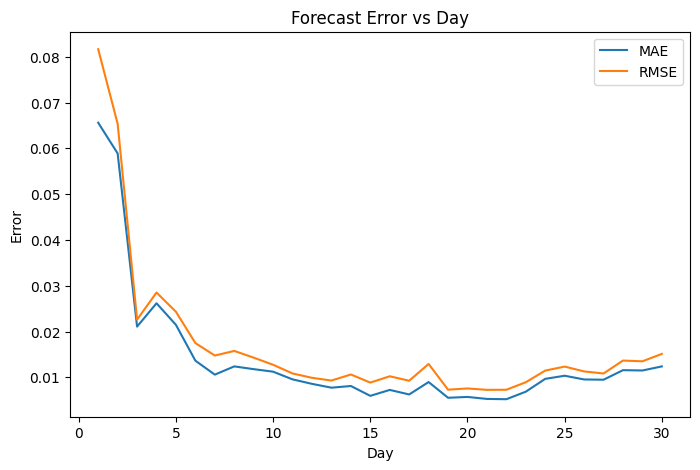

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(day_metrics.index, day_metrics["MAE"], label="MAE")
plt.plot(day_metrics.index, day_metrics["RMSE"], label="RMSE")
plt.xlabel("Day")
plt.ylabel("Error")
plt.title("Forecast Error vs Day")
plt.legend()
plt.show()


In [17]:
import matplotlib.pyplot as plt
import numpy as np

day_cols = [c for c in df.columns if c.startswith("day_")]

def plot_true_vs_pred(model, df, mix_idx):
    row = df.iloc[mix_idx]

    mix_features = row.drop(day_cols + ["Mix_name"], errors="ignore")
    true = row[day_cols].values.astype(float)
    pred = predict_curve(model, mix_features, days=30)

    days = np.arange(1, 31)

    plt.figure(figsize=(6, 4))
    plt.plot(days, true, marker="o", label="Original")
    plt.plot(days, pred, marker="x", linestyle="--", label="Predicted")
    plt.xlabel("Day")
    plt.ylabel("Strength")
    plt.title(f"Mix {mix_idx}: Original vs Predicted")
    plt.legend()
    plt.grid(True)
    plt.show()


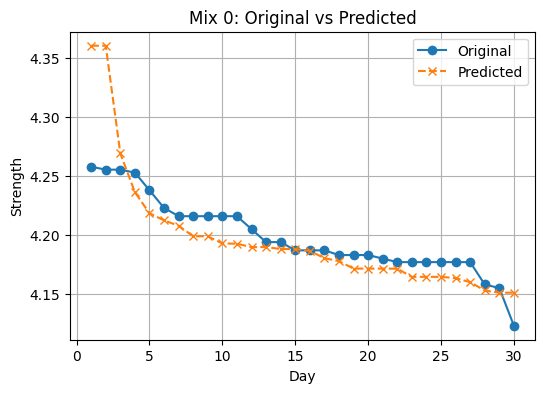

In [18]:
plot_true_vs_pred(model, df, mix_idx=0)


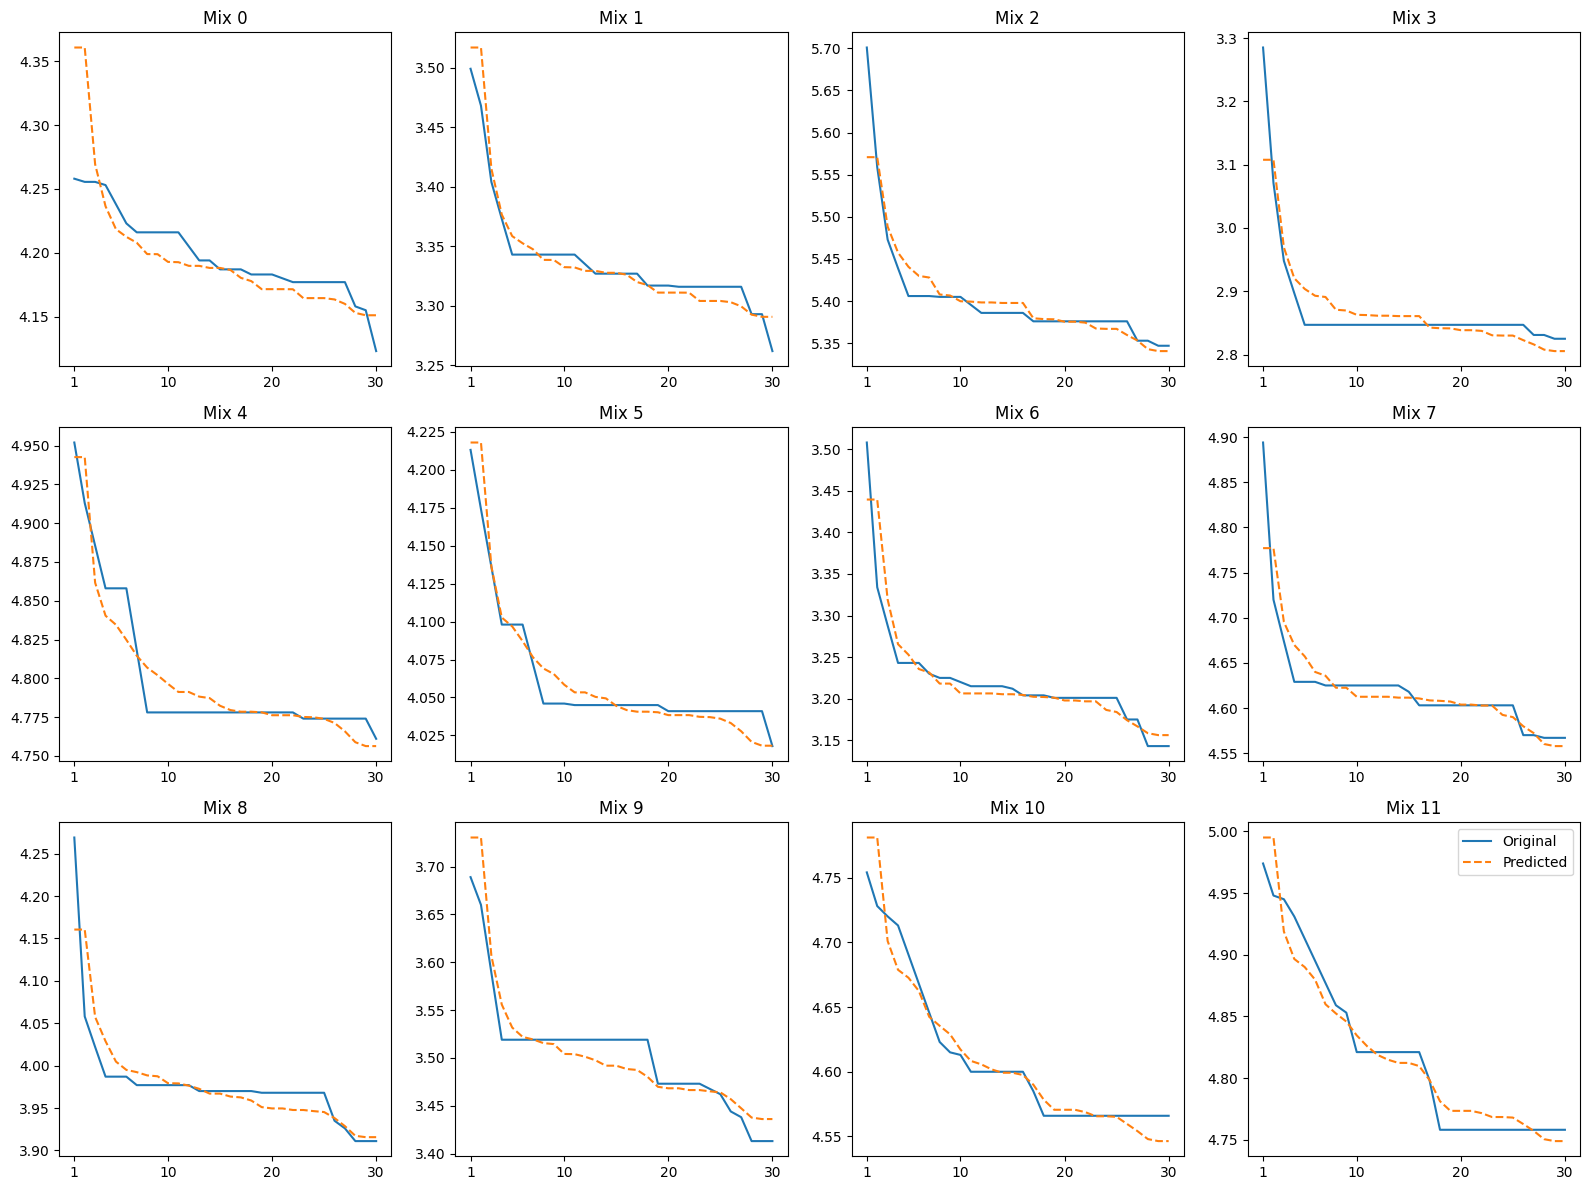

In [19]:
n_plots = min(12, len(df))   # show first 12 mixes
cols = 4
rows = (n_plots + cols - 1) // cols

plt.figure(figsize=(16, rows * 4))

for i in range(n_plots):
    row = df.iloc[i]

    mix_features = row.drop(day_cols + ["Mix_name"], errors="ignore")
    true = row[day_cols].values.astype(float)
    pred = predict_curve(model, mix_features, days=30)

    plt.subplot(rows, cols, i + 1)
    plt.plot(range(1, 31), true, label="Original")
    plt.plot(range(1, 31), pred, linestyle="--", label="Predicted")
    plt.title(f"Mix {i}")
    plt.xticks([1, 10, 20, 30])

plt.legend()
plt.tight_layout()
plt.show()


In [22]:
corr = df[df.columns[2:17]].corr(method="pearson")


In [23]:
corr

,print_type_Cast,print_type_Printed,Nano-Silica,Fly_ash,Ultrafine_Fly_ash,Ordinary_Portland_Cement,Binder_Weight,SP,VMA,Glass_fiber,PP_fiber,Sand,Water,Mix_Weight,day_01
print_type_Cast,1.000000,-1.000000,NaN,NaN,NaN,NaN,NaN,0.055556,NaN,-0.050506,0.080943,NaN,NaN,0.070869,0.275426
print_type_Printed,-1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,-0.055556,NaN,0.050506,-0.080943,NaN,NaN,-0.070869,-0.275426
Nano-Silica,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fly_ash,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ultrafine_Fly_ash,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ordinary_Portland_Cement,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Binder_Weight,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SP,0.055556,-0.055556,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,-0.909110,0.906507,NaN,NaN,0.415057,0.221798
VMA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Glass_fiber,-0.050506,0.050506,NaN,NaN,NaN,NaN,NaN,-0.909110,NaN,1.000000,-0.824115,NaN,NaN,-0.116500,-0.238535
